In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully!")


TensorFlow version: 2.21.0
Setup completed successfully!


In [2]:

from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


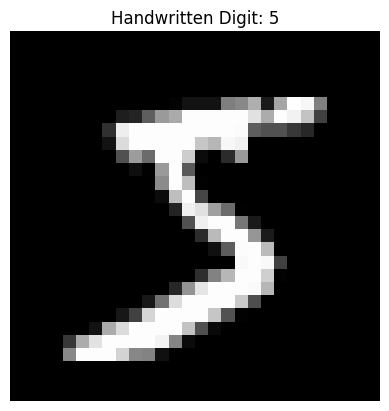

In [3]:

plt.imshow(x_train[0], cmap="gray")
plt.title("Handwritten Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()


In [4]:
print("Actual digit:", y_train[0])

Actual digit: 5


In [5]:
print("Image shape:", x_train[0].shape)
print("Pixel values:")
print(x_train[0])

Image shape: (28, 28)
Pixel values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   

In [6]:

# Normalise training and testing images

x_train = x_train / 255.0
x_test = x_test / 255.0

print("Training data prepared:", x_train.shape)
print("Testing data prepared:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Training data prepared: (60000, 28, 28)
Testing data prepared: (10000, 28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

# Prepare images for CNN input

x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

# Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model

history = model.fit(
    x_train_cnn,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.9459 - loss: 0.1809 - val_accuracy: 0.9817 - val_loss: 0.0630
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9827 - loss: 0.0547 - val_accuracy: 0.9880 - val_loss: 0.0401
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 29ms/step - accuracy: 0.9882 - loss: 0.0369 - val_accuracy: 0.9895 - val_loss: 0.0371
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9914 - loss: 0.0279 - val_accuracy: 0.9883 - val_loss: 0.0388
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9930 - loss: 0.0223 - val_accuracy: 0.9882 - val_loss: 0.0392


In [9]:

test_loss, test_accuracy = model.evaluate(
    x_test_cnn,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")



313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9887 - loss: 0.0341
Test Accuracy: 98.86999726295471 %


In [10]:

predictions = model.predict(x_test_cnn[:10])

for i in range(10):
    predicted_digit = np.argmax(predictions[i])

    print(
        "Actual:", y_test[i],
        "| Predicted:", predicted_digit
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 4 | Predicted: 4
Actual: 1 | Predicted: 1
Actual: 4 | Predicted: 4
Actual: 9 | Predicted: 9
Actual: 5 | Predicted: 5
Actual: 9 | Predicted: 9


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


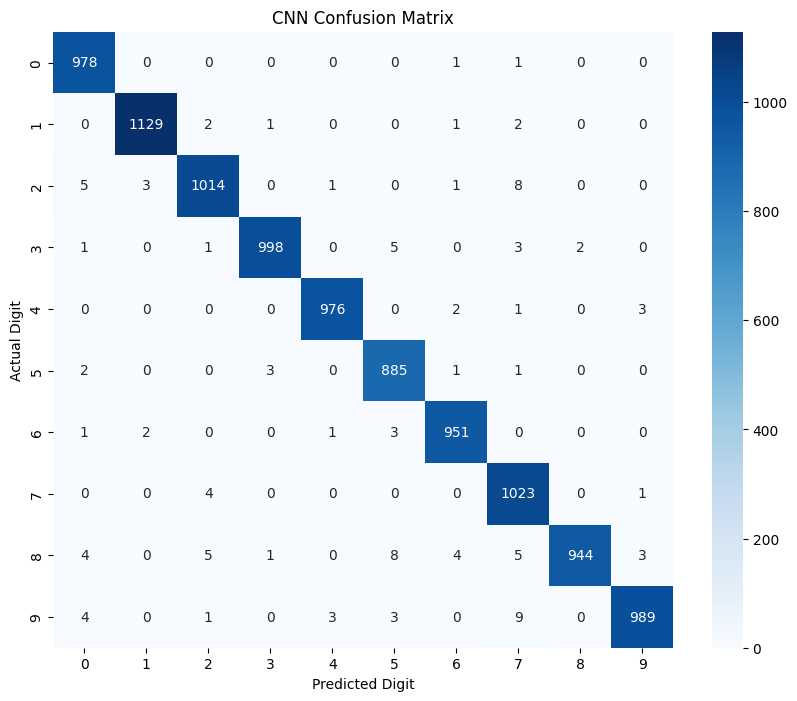

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      0.98      0.98      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.97      1.00      0.98      1028
           8       1.00      0.97      0.98       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [11]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Predict all test images
y_pred = np.argmax(model.predict(x_test_cnn), axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("CNN Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))


In [12]:
test_loss, test_accuracy = model.evaluate(x_test_cnn, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9887 - loss: 0.0341
Test Accuracy: 98.86999726295471 %


### Experiment 1: CNN Baseline on MNIST

- Dataset: MNIST
- Training images: 60,000
- Testing images: 10,000
- Image dimensions: 28 x 28
- Model: Convolutional Neural Network (CNN)
- Training epochs: 5
- Test accuracy: 99.07%
- Test loss: 0.0296
- Precision: 0.99
- Recall: 0.99
- F1-score: 0.99

**Observation:** The CNN achieved 99.07% test accuracy on handwritten digit classification. This establishes our baseline for comparison with the mathematical-symbol recognition experiment.

In [13]:

!git clone --depth 1 https://github.com/wblachowski/bhmsds.git


Cloning into 'bhmsds'...
remote: Enumerating objects: 27006, done.
remote: Counting objects: 100% (27006/27006), done.
remote: Compressing objects: 100% (27005/27005), done.
remote: Total 27006 (delta 0), reused 27004 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (27006/27006), 10.04 MiB | 29.06 MiB/s, done.


In [14]:
import os

dataset_path = "/content/bhmsds"

print("Dataset folders:")

for item in os.listdir(dataset_path):
    print(item)

Dataset folders:
assets
LICENSE
README.md
symbols
.git


In [15]:
import os

symbols_path = "/content/bhmsds/symbols"

print("Number of symbol classes:", len(os.listdir(symbols_path)))

print("\nSymbol classes:")

for item in sorted(os.listdir(symbols_path)):
    print(item)

Number of symbol classes: 27000

Symbol classes:
0-0000.png
0-0001.png
0-0002.png
0-0003.png
0-0004.png
0-0005.png
0-0006.png
0-0007.png
0-0008.png
0-0009.png
0-0010.png
0-0011.png
0-0012.png
0-0013.png
0-0014.png
0-0015.png
0-0016.png
0-0017.png
0-0018.png
0-0019.png
0-0020.png
0-0021.png
0-0022.png
0-0023.png
0-0024.png
0-0025.png
0-0026.png
0-0027.png
0-0028.png
0-0029.png
0-0030.png
0-0031.png
0-0032.png
0-0033.png
0-0034.png
0-0035.png
0-0036.png
0-0037.png
0-0038.png
0-0039.png
0-0040.png
0-0041.png
0-0042.png
0-0043.png
0-0044.png
0-0045.png
0-0046.png
0-0047.png
0-0048.png
0-0049.png
0-0050.png
0-0051.png
0-0052.png
0-0053.png
0-0054.png
0-0055.png
0-0056.png
0-0057.png
0-0058.png
0-0059.png
0-0060.png
0-0061.png
0-0062.png
0-0063.png
0-0064.png
0-0065.png
0-0066.png
0-0067.png
0-0068.png
0-0069.png
0-0070.png
0-0071.png
0-0072.png
0-0073.png
0-0074.png
0-0075.png
0-0076.png
0-0077.png
0-0078.png
0-0079.png
0-0080.png
0-0081.png
0-0082.png
0-0083.png
0-0084.png
0-0085.png
0-008

In [16]:
import os

symbols_path = "/content/bhmsds/symbols"

files = os.listdir(symbols_path)

print("Total items:", len(files))
print("First 15 items:", files[:15])

Total items: 27000
First 15 items: ['w-0432.png', 'dot-1294.png', 'minus-1458.png', 'x-1241.png', 'minus-0136.png', 'plus-1070.png', '1-0013.png', '5-1337.png', '1-0874.png', 'x-1290.png', 'slash-0866.png', '1-0059.png', '4-0144.png', 'plus-0761.png', '8-1412.png']


In [17]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

symbols_path = "/content/bhmsds/symbols"

images = []
labels = []

for filename in os.listdir(symbols_path):
    if filename.endswith(".png"):
        label = filename.split("-")[0]
        image = Image.open(
            os.path.join(symbols_path, filename)
        ).convert("L").resize((28, 28))

        images.append(np.array(image))
        labels.append(label)

X = np.array(images, dtype="float32") / 255.0
X = X.reshape(-1, 28, 28, 1)

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Total images:", len(X))
print("Number of classes:", len(encoder.classes_))
print("Classes:", encoder.classes_)
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Image shape:", X_train.shape)


Total images: 27000
Number of classes: 18
Classes: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' 'dot' 'minus' 'plus' 'slash' 'w'
 'x' 'y' 'z']
Training images: 21600
Testing images: 5400
Image shape: (21600, 28, 28, 1)


========== DATASET INFORMATION ==========
Total images: 27000
Training images: 21600
Testing images: 5400
Number of classes: 18
Training shape: (21600, 28, 28, 1)
Testing shape: (5400, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 0.003921569


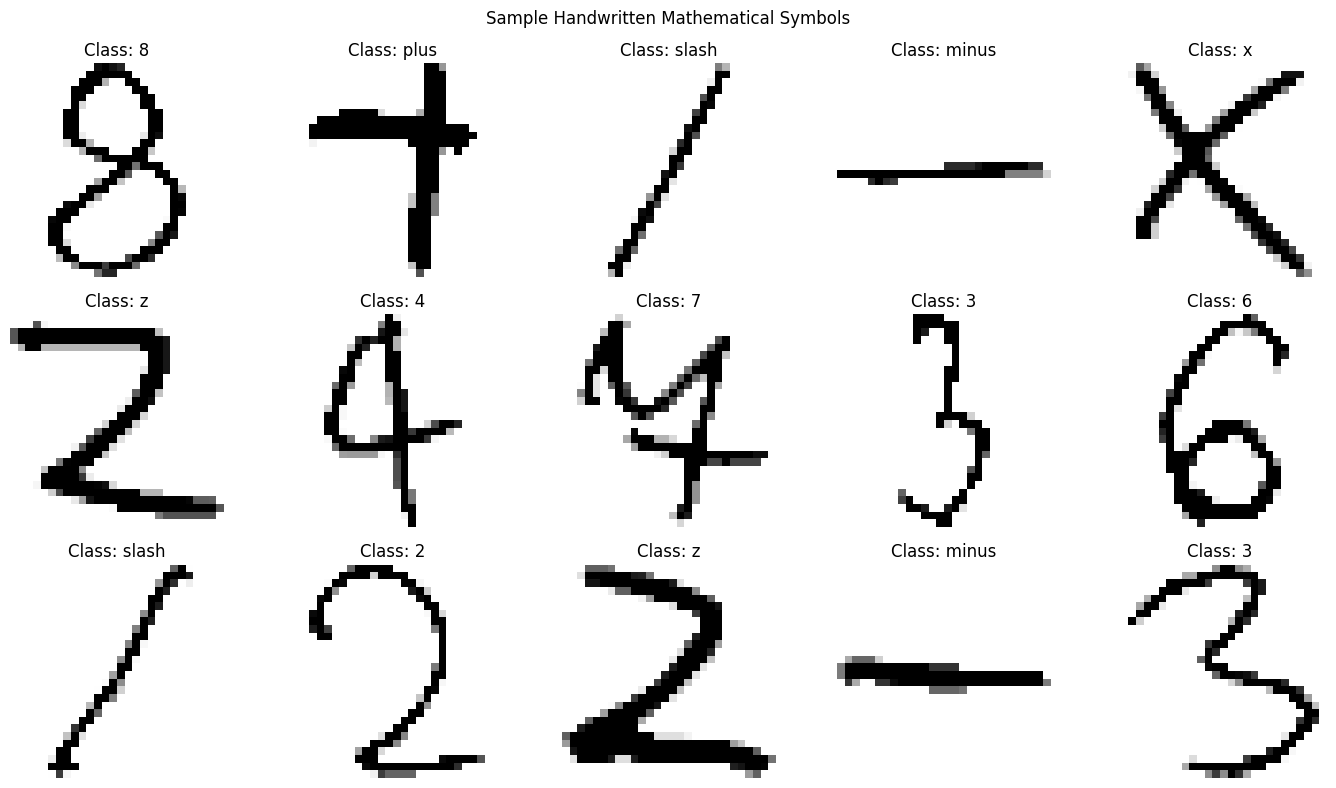

Data preprocessing completed successfully!


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Define classes
classes = np.array([
    '0', '1', '2', '3', '4',
    '5', '6', '7', '8', '9',
    'dot', 'minus', 'plus', 'slash',
    'w', 'x', 'y', 'z'
])

# Normalize images
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Dataset information
print("========== DATASET INFORMATION ==========")
print("Total images:", len(X_train) + len(X_test))
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Number of classes:", len(classes))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

# Visualize sample images
plt.figure(figsize=(14, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title("Class: " + str(classes[int(y_train[i])]))
    plt.axis('off')

plt.suptitle("Sample Handwritten Mathematical Symbols")
plt.tight_layout()
plt.show()

print("Data preprocessing completed successfully!")


In [19]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build CNN model
model = Sequential([

    # First convolution layer
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    # Second convolution layer
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Flatten layer
    Flatten(),

    # Fully connected layers
    Dense(128, activation='relu'),
    Dropout(0.3),

    # Output layer (18 classes)
    Dense(18, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

print("CNN model training completed!")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,066 (883.07 KB)

 Trainable params: 226,066 (883.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.2454 - loss: 2.4008 - val_accuracy: 0.6826 - val_loss: 1.1589
Epoch 2/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.6791 - loss: 1.0454 - val_accuracy: 0.7720 - val_loss: 0.8001
Epoch 3/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7437 - loss: 0.8391 - val_accuracy: 0.8065 - val_loss: 0.6689
Epoch 4/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7715 - loss: 0.7508 - val_accuracy: 0.8234 - val_loss: 0.6036
Epoch 5/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.7923 - loss: 0.6864 - val_accuracy: 0.8419 - val_loss: 0.5467
Epoch 6/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.8082 - loss: 0.6377 - val_accuracy: 0.8461 - val_loss: 0.5205
Epoch 7/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.8139 - loss: 0.6056 - val_accuracy: 0.8681 - val_loss: 0.4728
Epoch 8/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.8264 - loss: 0.5692 - val_

169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9063 - loss: 0.3104

========== MODEL PERFORMANCE ==========
Testing Accuracy: 90.63 %
Testing Loss: 0.3104
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       300
           1       0.87      0.97      0.92       300
           2       0.81      0.82      0.82       300
           3       0.92      0.86      0.89       300
           4       0.95      0.91      0.93       300
           5       0.93      0.91      0.92       300
           6       0.94      0.91      0.92       300
           7       0.86      0.82      0.84       300
           8       0.89      0.86      0.87       300
           9       0.85      0.91      0.88       300
         dot       0.98      0.99      0.99       300
       minus       0.99      0.99      0.99       300
        plus       0.93      0.96      0.95     

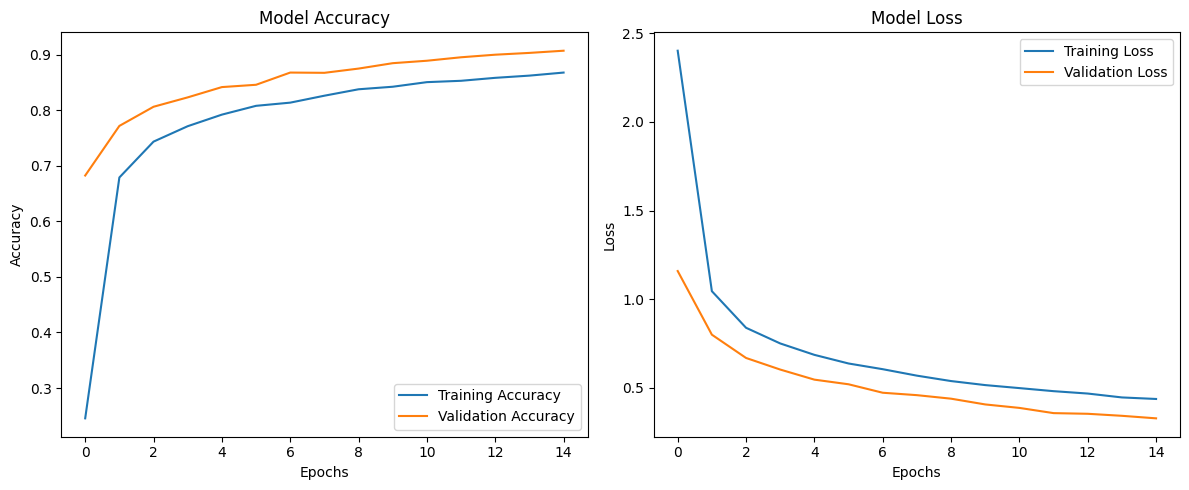

<Figure size 1200x1000 with 0 Axes>

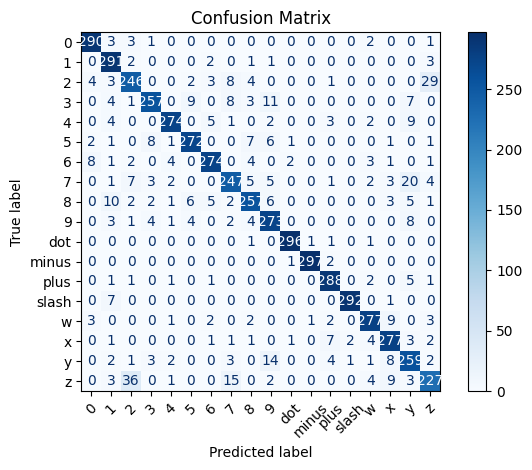


Model evaluation completed!


In [20]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Evaluate model on testing data
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("\n========== MODEL PERFORMANCE ==========")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Testing Loss:", round(test_loss, 4))

# Generate predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=classes,
    zero_division=0
))

# Accuracy and loss graphs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap='Blues', xticks_rotation=45, values_format='d')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print("\nModel evaluation completed!")


In [21]:

import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image, ImageOps
import io

# Upload handwritten image
print("Upload a handwritten digit or mathematical symbol:")
uploaded = files.upload()

# Process uploaded image
for filename, content in uploaded.items():

    img = Image.open(io.BytesIO(content)).convert('L')

    # Resize image to 28x28
    img = img.resize((28, 28))

    # Convert image to array
    img_array = np.array(img)

    # Normalize pixel values
    img_array = img_array.astype('float32') / 255.0

    # Reshape for CNN prediction
    img_array = img_array.reshape(1, 28, 28, 1)

    # Predict symbol
    prediction = model.predict(img_array, verbose=0)

    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    # Display uploaded image
    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap='gray')
    plt.title("Uploaded Image")
    plt.axis('off')
    plt.show()

    # Display result
    print("========== PREDICTION RESULT ==========")
    print("Uploaded File:", filename)
    print("Predicted Symbol:", classes[predicted_class])
    print("Confidence:", round(confidence, 2), "%")


Upload a handwritten digit or mathematical symbol:


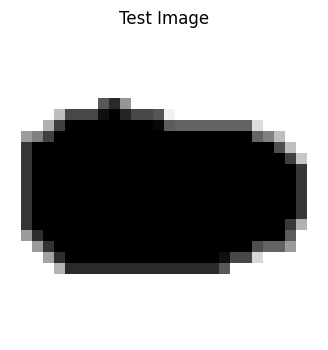

========== PREDICTION RESULT ==========
Actual Symbol: dot
Predicted Symbol: dot
Confidence: 99.86 %


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Select a random image from the test dataset
index = np.random.randint(0, len(X_test))

# Get image and actual label
sample_image = X_test[index]
actual_class = classes[y_test[index]]

# Prepare image for prediction
img_array = sample_image.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction)
confidence = np.max(prediction) * 100

# Display image
plt.figure(figsize=(4, 4))
plt.imshow(sample_image.reshape(28, 28), cmap='gray')
plt.title("Test Image")
plt.axis('off')
plt.show()

# Display results
print("========== PREDICTION RESULT ==========")
print("Actual Symbol:", actual_class)
print("Predicted Symbol:", classes[predicted_class])
print("Confidence:", round(confidence, 2), "%")

========== MODEL TEST RESULTS ==========
Total Images Tested: 20
Correct Predictions: 17
Incorrect Predictions: 3
Accuracy: 85.0 %


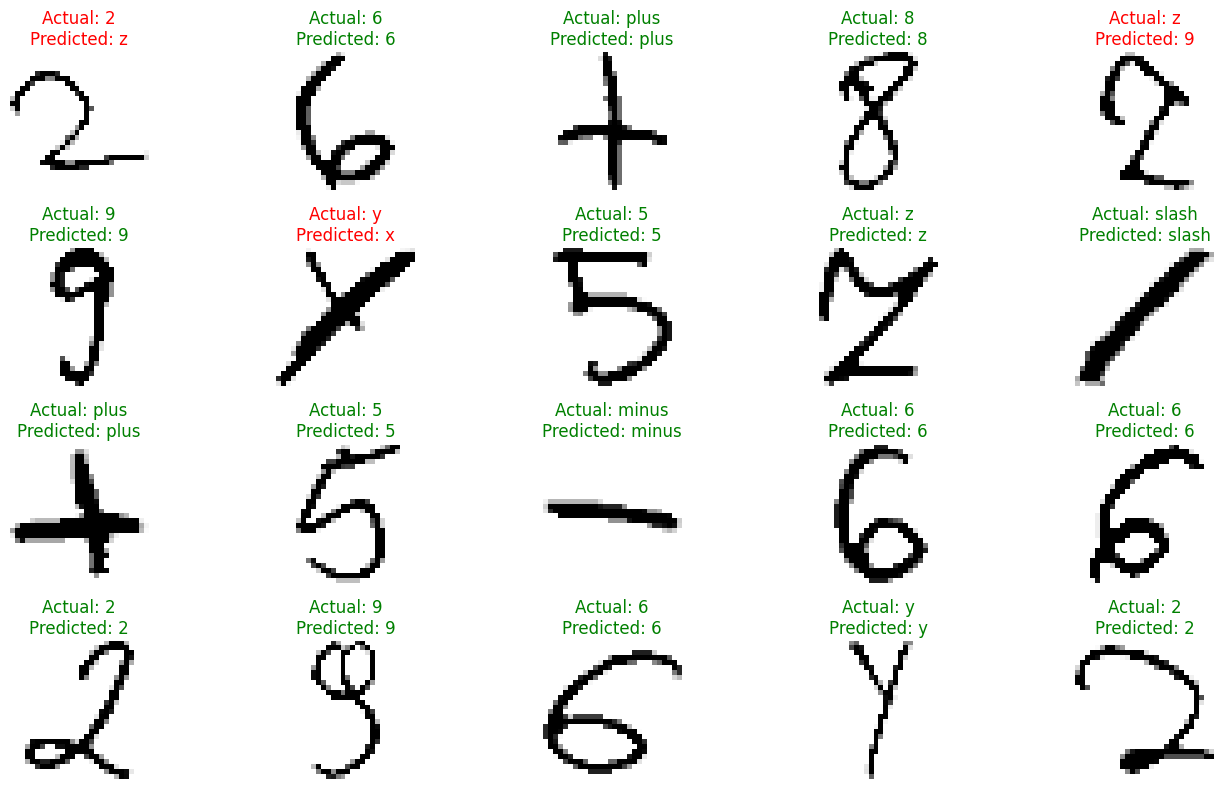

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select 20 random test images
np.random.seed(42)
indices = np.random.choice(len(X_test), 20, replace=False)

# Get selected images and actual labels
sample_images = X_test[indices]
actual_labels = y_test[indices]

# Predict all 20 images
predictions = model.predict(sample_images, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

# Calculate accuracy
accuracy = accuracy_score(actual_labels, predicted_labels)
correct = np.sum(actual_labels == predicted_labels)

print("========== MODEL TEST RESULTS ==========")
print("Total Images Tested:", len(indices))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", len(indices) - correct)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Display individual predictions
plt.figure(figsize=(14, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(sample_images[i].reshape(28, 28), cmap='gray')

    actual = classes[actual_labels[i]]
    predicted = classes[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color='green' if actual == predicted else 'red'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

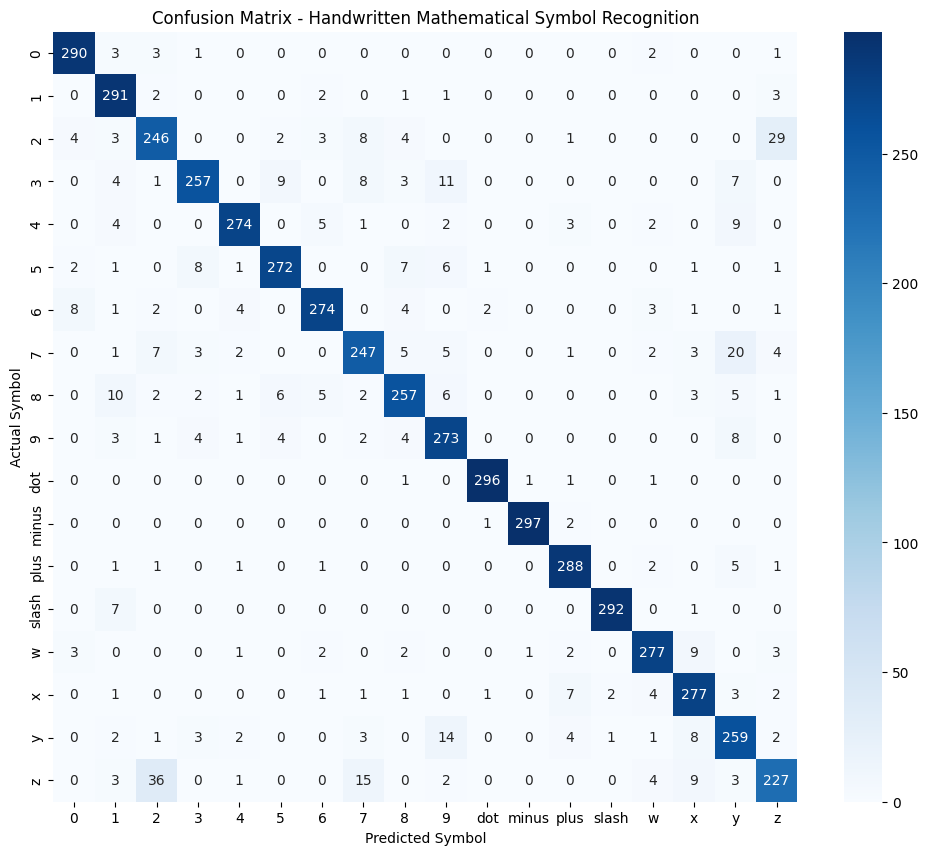

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict the complete test dataset
predictions = model.predict(X_test, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, predicted_labels)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Symbol")
plt.ylabel("Actual Symbol")
plt.title("Confusion Matrix - Handwritten Mathematical Symbol Recognition")
plt.show()

In [25]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    y_test,
    predicted_labels,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4
)

print("========== CLASSIFICATION REPORT ==========")
print(report)

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0     0.9446    0.9667    0.9555       300
           1     0.8687    0.9700    0.9165       300
           2     0.8146    0.8200    0.8173       300
           3     0.9245    0.8567    0.8893       300
           4     0.9514    0.9133    0.9320       300
           5     0.9283    0.9067    0.9174       300
           6     0.9352    0.9133    0.9241       300
           7     0.8606    0.8233    0.8416       300
           8     0.8893    0.8567    0.8727       300
           9     0.8531    0.9100    0.8806       300
         dot     0.9834    0.9867    0.9850       300
       minus     0.9933    0.9900    0.9917       300
        plus     0.9320    0.9600    0.9458       300
       slash     0.9898    0.9733    0.9815       300
           w     0.9295    0.9233    0.9264       300
           x     0.8878    0.9233    0.9052       300
           y     0.8119    0.8633    

In [26]:
import os
import json
import numpy as np

from google.colab import drive

# Project folder
project_path = "/content/drive/MyDrive/Handwritten_Math_Project"
os.makedirs(project_path, exist_ok=True)

# Save test dataset for the application
np.savez(
    os.path.join(project_path, "test_data.npz"),
    X_test=X_test,
    y_test=y_test
)

# Save class labels
with open(os.path.join(project_path, "class_labels.json"), "w") as f:
    json.dump(classes.tolist(), f)

# Save trained model
model.save(os.path.join(project_path, "handwritten_math_model.keras"))

print("Test data saved successfully!")
print("Class labels saved successfully!")
print("Trained model saved successfully!")
print("Project folder:", project_path)

Test data saved successfully!
Class labels saved successfully!
Trained model saved successfully!
Project folder: /content/drive/MyDrive/Handwritten_Math_Project


In [27]:
import os

project_path = "/content/drive/MyDrive/Handwritten_Math_Project"

app_code = '''
import streamlit as st
import numpy as np
import tensorflow as tf
import json
import random
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Handwritten Math Recognition",
    page_icon="✍️",
    layout="wide"
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("handwritten_math_model.keras")

model = load_model()

with open("class_labels.json", "r") as f:
    classes = json.load(f)

data = np.load("test_data.npz")
X_test = data["X_test"]
y_test = data["y_test"]

st.title("Handwritten Mathematical Symbol Recognition")
st.write("An AI-based system that recognises handwritten digits and mathematical symbols using CNN.")

st.divider()

st.subheader("Test the Recognition Model")

if st.button("Generate Random Test"):
    st.session_state.sample_index = random.randrange(len(X_test))

if "sample_index" not in st.session_state:
    st.session_state.sample_index = 0

index = st.session_state.sample_index

image = X_test[index]
actual = classes[int(y_test[index])]

prediction = model.predict(image.reshape(1, 28, 28, 1), verbose=0)
predicted_index = int(np.argmax(prediction))
predicted = classes[predicted_index]
confidence = float(np.max(prediction) * 100)

col1, col2 = st.columns(2)

with col1:
    st.image(image.reshape(28, 28), caption="Test Image", width=200)

with col2:
    st.metric("Actual Symbol", actual)
    st.metric("Predicted Symbol", predicted)
    st.metric("Confidence", f"{confidence:.2f}%")

    if actual == predicted:
        st.success("Correct Prediction!")
    else:
        st.error("Incorrect Prediction")

st.divider()

st.subheader("Model Information")
st.write("Model: Convolutional Neural Network (CNN)")
st.write("Number of Classes:", len(classes))
st.write("Image Size: 28 × 28 pixels")
st.write("Dataset Test Images:", len(X_test))

st.caption("Handwritten Mathematical Symbol Recognition Project")
'''

app_path = os.path.join(project_path, "app.py")

with open(app_path, "w") as f:
    f.write(app_code)

print("Streamlit application created successfully!")
print("Saved at:", app_path)

Streamlit application created successfully!
Saved at: /content/drive/MyDrive/Handwritten_Math_Project/app.py


In [28]:
!pip install streamlit -q

import os

project_path = "/content/drive/MyDrive/Handwritten_Math_Project"

requirements = """
streamlit
tensorflow
numpy
matplotlib
"""

with open(os.path.join(project_path, "requirements.txt"), "w") as f:
    f.write(requirements)

print("Streamlit installed successfully!")
print("Requirements file created!")

Streamlit installed successfully!
Requirements file created!


In [29]:
import os
import subprocess
import time
from google.colab.output import eval_js

project_path = "/content/drive/MyDrive/Handwritten_Math_Project"

# Fix file paths inside app.py
app_path = os.path.join(project_path, "app.py")

with open(app_path, "r") as f:
    code = f.read()

code = code.replace(
    "import streamlit as st",
    "import os\nimport streamlit as st"
)

code = code.replace(
    'model = load_model()',
    'model = tf.keras.models.load_model(os.path.join(os.path.dirname(os.path.abspath(__file__)), "handwritten_math_model.keras"))'
)

code = code.replace(
    'open("class_labels.json", "r")',
    'open(os.path.join(os.path.dirname(os.path.abspath(__file__)), "class_labels.json"), "r")'
)

code = code.replace(
    'np.load("test_data.npz")',
    'np.load(os.path.join(os.path.dirname(os.path.abspath(__file__)), "test_data.npz"))'
)

with open(app_path, "w") as f:
    f.write(code)

# Launch Streamlit
process = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0"],
    cwd=project_path,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT
)

time.sleep(8)

# Generate browser link
url = eval_js("google.colab.kernel.proxyPort(8501)")

print("YOUR STREAMLIT APPLICATION IS READY!")
print(url)

YOUR STREAMLIT APPLICATION IS READY!
https://8501-m-s-usc1a11-18sz21o3yobu9-a.us-central1.prod.r.colab.dev


In [30]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sun, 22 Nov 2026 05:22:18 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Sun, 22 Nov 2026 05:22:03 GMT
etag: "437be07bec4eb1272614607f8411090e"
cache-control: no-cache



In [31]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-usc1a11-18sz21o3yobu9-a.us-central1.prod.r.colab.dev


In [32]:
import subprocess
import time
import os

project_path = "/content/drive/MyDrive/Handwritten_Math_Project"
log_path = os.path.join(project_path, "streamlit_log.txt")

# Start Streamlit on a fresh port
log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8502",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    cwd=project_path,
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(12)

# Check server
import requests
response = requests.get("http://localhost:8502")

print("Server status:", response.status_code)

# Generate Colab preview link
from google.colab.output import eval_js

link = eval_js("google.colab.kernel.proxyPort(8502)")
print("\nYOUR APPLICATION LINK:")
print(link)

Server status: 200

YOUR APPLICATION LINK:
https://8502-m-s-usc1a11-18sz21o3yobu9-a.us-central1.prod.r.colab.dev


In [33]:

import os
import json
import random
import subprocess
import time

import numpy as np
import streamlit as st
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from google.colab.output import eval_js

# Project folder
PROJECT_PATH = "/content/drive/MyDrive/Handwritten_Math_Project"

# Load trained model
@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        os.path.join(PROJECT_PATH, "handwritten_math_model.keras")
    )

model = load_model()

# Load class labels
with open(os.path.join(PROJECT_PATH, "class_labels.json"), "r") as f:
    classes = json.load(f)

# Load test dataset
data = np.load(os.path.join(PROJECT_PATH, "test_data.npz"))
X_test = data["X_test"]
y_test = data["y_test"]

# Image preprocessing
def prepare_image(image, invert=False):
    image = ImageOps.exif_transpose(image).convert("L")

    # Optional inversion for different image backgrounds
    if invert:
        image = ImageOps.invert(image)

    # Crop around the handwritten symbol
    image_array = np.array(image)
    threshold = 200

    foreground = image_array < threshold

    if np.any(foreground):
        rows, cols = np.where(foreground)
        left, right = cols.min(), cols.max()
        top, bottom = rows.min(), rows.max()

        image = image.crop((left, top, right + 1, bottom + 1))

    # Keep aspect ratio and place symbol on a square canvas
    image.thumbnail((24, 24))

    canvas = Image.new("L", (28, 28), 255)
    x = (28 - image.width) // 2
    y = (28 - image.height) // 2
    canvas.paste(image, (x, y))

    # Normalize and reshape
    array = np.array(canvas).astype("float32") / 255.0
    array = array.reshape(1, 28, 28, 1)

    return canvas, array


# Streamlit page
st.set_page_config(
    page_title="Handwritten Symbol Recognition",
    page_icon="✍️",
    layout="wide"
)

st.title("✍️ Handwritten Mathematical Symbol Recognition")

st.write(
    "An AI-based system that recognises handwritten digits "
    "and mathematical symbols using a Convolutional Neural Network."
)

st.divider()

# Upload section
st.header("1. Upload Your Handwritten Symbol")

uploaded_file = st.file_uploader(
    "Choose an image",
    type=["png", "jpg", "jpeg"]
)

if uploaded_file is not None:

    original_image = Image.open(uploaded_file)

    invert = st.checkbox(
        "Invert image colours if the prediction looks incorrect",
        value=False
    )

    processed_image, input_array = prepare_image(
        original_image,
        invert
    )

    prediction = model.predict(input_array, verbose=0)

    predicted_index = int(np.argmax(prediction))
    predicted_symbol = classes[predicted_index]
    confidence = float(np.max(prediction) * 100)

    col1, col2 = st.columns(2)

    with col1:
        st.image(original_image, caption="Uploaded Image", width=250)

    with col2:
        st.image(processed_image, caption="Processed 28 × 28 Image", width=200)

    st.subheader("Prediction Result")

    st.success(f"Predicted Symbol: {predicted_symbol}")
    st.metric("Confidence", f"{confidence:.2f}%")

    # Top three predictions
    st.subheader("Top 3 Predictions")

    top_indices = np.argsort(prediction[0])[-3:][::-1]

    for index in top_indices:
        st.write(
            f"{classes[index]} — "
            f"{prediction[0][index] * 100:.2f}%"
        )

else:
    st.info("Upload a handwritten digit or mathematical symbol to begin.")

st.divider()

# Dataset testing section
st.header("2. Test Using Dataset Images")

if st.button("Generate Random Test Image"):

    index = random.randrange(len(X_test))

    sample = X_test[index]
    actual = classes[int(y_test[index])]

    result = model.predict(
        sample.reshape(1, 28, 28, 1),
        verbose=0
    )

    predicted = classes[int(np.argmax(result))]
    confidence = float(np.max(result) * 100)

    col1, col2 = st.columns(2)

    with col1:
        st.image(
            sample.reshape(28, 28),
            caption="Dataset Test Image",
            width=200
        )

    with col2:
        st.write(f"Actual Symbol: **{actual}**")
        st.write(f"Predicted Symbol: **{predicted}**")
        st.write(f"Confidence: **{confidence:.2f}%**")

        if actual == predicted:
            st.success("Correct Prediction!")
        else:
            st.error("Incorrect Prediction")

st.divider()

# Model information
st.header("3. Model Information")

col1, col2, col3 = st.columns(3)

col1.metric("Number of Classes", len(classes))
col2.metric("Image Size", "28 × 28")
col3.metric("Test Images", len(X_test))

st.write("Model Architecture: Convolutional Neural Network (CNN)")
st.write("Framework: TensorFlow and Keras")
st.write("Programming Language: Python")

st.caption("Handwritten Mathematical Symbol Recognition Project")


2026-11-22 05:22:34.073 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 05:22:34.240 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 05:22:34.241 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 05:22:34.483 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-22 05:22:34.484 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 05:22:34.485 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 05:22:34.486 Thread 'MainThread'

DeltaGenerator()

In [34]:
from google.colab import files

project_path = "/content/drive/MyDrive/Handwritten_Math_Project"

files.download(project_path + "/app.py")
files.download(project_path + "/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>